In [1]:
from pathlib import Path
import pandas as pd

MEDIA_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\media.json"
)

if not MEDIA_PATH.is_file():
    raise FileNotFoundError(f"File non trovato: {MEDIA_PATH}")

print(f"Dimensione: {MEDIA_PATH.stat().st_size / 1024**2:.1f} MiB")

# Load the JSON file into a DataFrame
df = pd.read_json(MEDIA_PATH)

# Export the DataFrame to a CSV file in the same directory
CSV_PATH = MEDIA_PATH.with_suffix(".csv")
df.to_csv(CSV_PATH, index=False)

print(f"CSV salvato in: {CSV_PATH}")
print(f"Numero di record: {len(df):,}")
print(f"Versione pandas: {pd.__version__}")

# Display the first 5 rows
df.head()

Dimensione: 51.2 MiB
CSV salvato in: C:\Users\bucco\Desktop\Laboratory of Data Science\project\code_project\data\Project_Data\media.csv
Numero di record: 257,500
Versione pandas: 3.1.0


,id_media,media_url,truth_id,media_id
0,2,https://static-assets-1.truthsocial.com/tmtg:p...,37,2
1,2,https://static-assets-1.truthsocial.com/tmtg:p...,384189,2
2,2,https://static-assets-1.truthsocial.com/tmtg:p...,508873,2
3,5,https://static-assets-1.truthsocial.com/tmtg:p...,40,5
4,5,https://static-assets-1.truthsocial.com/tmtg:p...,386893,5


In [3]:
print(type(df))
print(df.columns.tolist())
print(df.dtypes)

<class 'pandas.DataFrame'>
['id_media', 'media_url', 'truth_id', 'media_id']
id_media     int64
media_url      str
truth_id     int64
media_id     int64
dtype: object


In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 257500 entries, 0 to 257499
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   id_media   257500 non-null  int64
 1   media_url  257500 non-null  str  
 2   truth_id   257500 non-null  int64
 3   media_id   257500 non-null  int64
dtypes: int64(3), str(1)
memory usage: 9.8 MB


In [5]:
df.describe()

,id_media,truth_id,media_id
count,257500.000000,257500.000000,257500.000000
mean,90413.659499,401685.727184,90413.659499
std,61975.832645,206933.663663,61975.832645
min,2.000000,37.000000,2.000000
25%,35046.750000,223820.500000,35046.750000
50%,78222.500000,401504.500000,78222.500000
75%,143867.250000,575198.250000,143867.250000
max,211832.000000,782306.000000,211832.000000


In [6]:
print(df["id_media"].equals(df["media_id"]))

True


In [7]:
# Step 1: Collect all rows belonging to exact-duplicate groups
all_duplicate_rows = df[df.duplicated(keep=False)].copy()

# Step 2: Display the first 5 rows belonging to duplicate groups
display(all_duplicate_rows)   
# The output should not be the same rows because here 
#I'm printing only the one of the duplicated rows 

# Step 3: Select the first duplicated occurrence
duplicate_rows = df[df.duplicated(keep="first")]

duplicate_index = duplicate_rows.index[0]

# Step 4: Retrieve the values of that row
duplicate_values = df.loc[duplicate_index]

# Step 5: Find rows with exactly the same values
# across all columns, including missing values
matching_rows = df.loc[
    df.eq(duplicate_values).all(axis=1)
    | (df.isna() & duplicate_values.isna()).all(axis=1)
]

# Step 6: Display the matching rows
display(matching_rows)

,id_media,media_url,truth_id,media_id
46407,27172,https://static-assets-1.truthsocial.com/tmtg:p...,115714,27172
46408,27172,https://static-assets-1.truthsocial.com/tmtg:p...,115714,27172
46413,27180,https://static-assets-1.truthsocial.com/tmtg:p...,115734,27180
46414,27180,https://static-assets-1.truthsocial.com/tmtg:p...,115734,27180
46416,27182,https://static-assets-1.truthsocial.com/tmtg:p...,115737,27182
46417,27182,https://static-assets-1.truthsocial.com/tmtg:p...,115737,27182
46418,27184,https://static-assets-1.truthsocial.com/tmtg:p...,115739,27184
46419,27184,https://static-assets-1.truthsocial.com/tmtg:p...,115739,27184


,id_media,media_url,truth_id,media_id
46407,27172,https://static-assets-1.truthsocial.com/tmtg:p...,115714,27172
46408,27172,https://static-assets-1.truthsocial.com/tmtg:p...,115714,27172


In [8]:

# Count duplicate rows, excluding the first occurrence
number_of_duplicates = df.duplicated().sum()

print("Number of duplicate rows:", number_of_duplicates)

Number of duplicate rows: 4


In [9]:
df["id_media"].is_unique

False

In [10]:
df["id_media"].duplicated().sum()

np.int64(72624)

In [12]:
df["media_url"].is_unique

False

In [13]:
df["id_media"].duplicated().sum()

np.int64(72624)

In [14]:
df["id_media"].duplicated().equals(
    df["media_url"].duplicated()
) 

True

In [15]:
df[["id_media", "media_url"]].duplicated().sum()

np.int64(72624)

In [16]:
df[
    df["id_media"].duplicated()
    != df["media_url"].duplicated()
]

,id_media,media_url,truth_id,media_id


In [17]:
df["truth_id"].is_unique

False

In [18]:
df["truth_id"].duplicated().sum()

np.int64(21010)

In [19]:
df["truth_id"].duplicated().equals(
    df["media_url"].duplicated()
) 

False

In [20]:
df.isnull().sum()

id_media     0
media_url    0
truth_id     0
media_id     0
dtype: int64

In [21]:
df["media_url"]

0         https://static-assets-1.truthsocial.com/tmtg:p...
1         https://static-assets-1.truthsocial.com/tmtg:p...
2         https://static-assets-1.truthsocial.com/tmtg:p...
3         https://static-assets-1.truthsocial.com/tmtg:p...
4         https://static-assets-1.truthsocial.com/tmtg:p...
                                ...                        
257495    https://static-assets-1.truthsocial.com/tmtg:p...
257496    https://static-assets-1.truthsocial.com/tmtg:p...
257497    https://static-assets-1.truthsocial.com/tmtg:p...
257498    https://static-assets-1.truthsocial.com/tmtg:p...
257499    https://static-assets-1.truthsocial.com/tmtg:p...
Name: media_url, Length: 257500, dtype: str

In [22]:
print("CARDINALITY ANALYSIS")
print("--------------------")

print(f"Total records: {len(df):,}")
print(f"Unique media IDs: {df['id_media'].nunique():,}")
print(f"Unique media URLs: {df['media_url'].nunique():,}")
print(f"Unique Truth IDs: {df['truth_id'].nunique():,}")

print("\nUnique values per column:")
display(df.nunique())

CARDINALITY ANALYSIS
--------------------
Total records: 257,500
Unique media IDs: 184,876
Unique media URLs: 184,876
Unique Truth IDs: 236,490

Unique values per column:


id_media     184876
media_url    184876
truth_id     236490
media_id     184876
dtype: int64

In [23]:
# Count unique URLs associated with each media ID
urls_per_id = df.groupby("id_media")["media_url"].nunique()

# Count unique media IDs associated with each URL
ids_per_url = df.groupby("media_url")["id_media"].nunique()

print("Media IDs associated with multiple URLs:",
      (urls_per_id > 1).sum())

print("Media URLs associated with multiple IDs:",
      (ids_per_url > 1).sum())

Media IDs associated with multiple URLs: 0
Media URLs associated with multiple IDs: 0


MEDIA PER TRUTH
--------------------


count    236490.000000
mean          1.088824
std           0.425777
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           8.000000
Name: id_media, dtype: float64

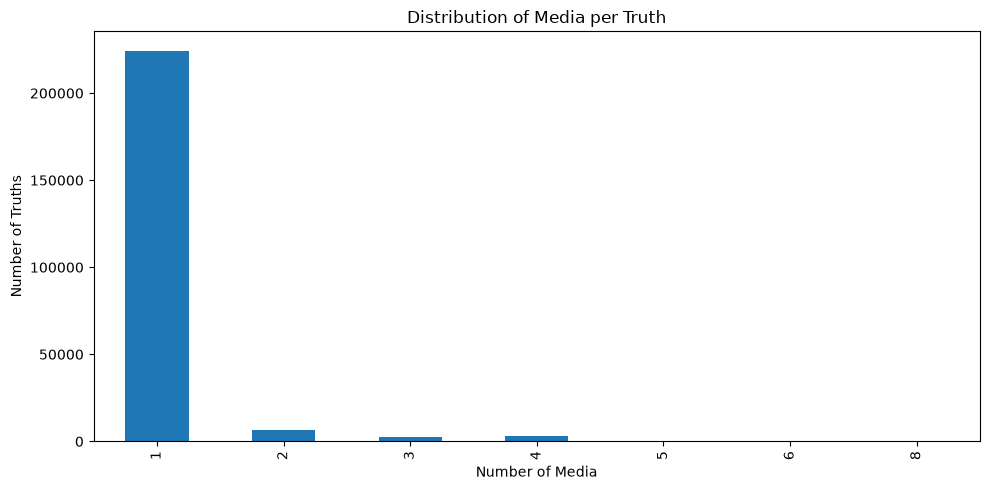

In [24]:
import matplotlib.pyplot as plt

# Count unique media associated with each Truth
media_per_truth = df.groupby("truth_id")["id_media"].nunique()

print("MEDIA PER TRUTH")
print("--------------------")
display(media_per_truth.describe())

# Frequency distribution
distribution = media_per_truth.value_counts().sort_index()

plt.figure(figsize=(10, 5))
distribution.plot(kind="bar")

plt.title("Distribution of Media per Truth")
plt.xlabel("Number of Media")
plt.ylabel("Number of Truths")
plt.tight_layout()
plt.show()

In [25]:
# Count distinct Truths associated with each media
media_reuse = (
    df.groupby("id_media")["truth_id"]
      .nunique()
      .sort_values(ascending=False)
)

print("MEDIA REUSE STATISTICS")
print("----------------------")

display(media_reuse.describe())

print("Media appearing in more than one Truth:",
      (media_reuse > 1).sum())

print("\nTop 10 most reused media:")
display(media_reuse.head(10))

MEDIA REUSE STATISTICS
----------------------


count    184876.000000
mean          1.392804
std           2.238594
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         345.000000
Name: truth_id, dtype: float64

Media appearing in more than one Truth: 22903

Top 10 most reused media:


id_media
233      345
428      125
273      105
26818    104
129       88
11200     79
28087     75
275       75
234       72
522       67
Name: truth_id, dtype: int64

In [26]:
# Convert URLs to strings
urls = df["media_url"].astype("string")

# Check for empty URLs
empty_urls = urls.isna() | urls.str.strip().eq("")

# Check URL prefixes
valid_prefix = urls.str.match(
    r"^https?://",
    na=False
)

print("MEDIA URL QUALITY")
print("-----------------")
print("Empty URLs:", empty_urls.sum())
print("URLs without HTTP/HTTPS prefix:",
      (~valid_prefix & ~empty_urls).sum())

# Inspect potentially problematic URLs
invalid_urls = df[empty_urls | ~valid_prefix]

display(invalid_urls.head(10))

MEDIA URL QUALITY
-----------------
Empty URLs: 0
URLs without HTTP/HTTPS prefix: 0


,id_media,media_url,truth_id,media_id


In [27]:
from pathlib import Path
import pandas as pd

# Define the path to the truths dataset
TRUTHS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\truths.csv"
)

# Check if the file exists
if not TRUTHS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {TRUTHS_PATH}")

# Load only the ID column to reduce memory usage
truths_df = pd.read_csv(
    TRUTHS_PATH,
    usecols=["id"]
)

# Ensure consistent data types for comparison
media_truth_ids = set(
    pd.to_numeric(df["truth_id"], errors="coerce").dropna()
)

truth_ids = set(
    pd.to_numeric(truths_df["id"], errors="coerce").dropna()
)

# Check referential integrity
matched_ids = media_truth_ids & truth_ids
unmatched_ids = media_truth_ids - truth_ids

# Calculate match rate
match_rate = (
    len(matched_ids) / len(media_truth_ids) * 100
    if media_truth_ids else 0
)

print("REFERENTIAL INTEGRITY CHECK")
print("---------------------------")
print(f"Unique Truth IDs in media.json: {len(media_truth_ids):,}")
print(f"Unique Truth IDs in truths.csv: {len(truth_ids):,}")
print(f"Matched Truth IDs: {len(matched_ids):,}")
print(f"Unmatched Truth IDs: {len(unmatched_ids):,}")
print(f"Match rate: {match_rate:.2f}%")

# Calculate the number of media records associated with unmatched Truth IDs
media_truth_numeric = pd.to_numeric(df["truth_id"], errors="coerce")

unmatched_records = df[
    media_truth_numeric.isin(unmatched_ids)
]

unmatched_percentage = (
    len(unmatched_records) / len(df) * 100
    if len(df) > 0 else 0
)

print("\nUNMATCHED MEDIA RECORDS")
print("-----------------------")
print(f"Total media records: {len(df):,}")
print(f"Unmatched media records: {len(unmatched_records):,}")
print(f"Percentage of affected records: {unmatched_percentage:.2f}%")

# Display a sample of unmatched records
display(unmatched_records.head(10))

REFERENTIAL INTEGRITY CHECK
---------------------------
Unique Truth IDs in media.json: 236,490
Unique Truth IDs in truths.csv: 1,038,821
Matched Truth IDs: 137,849
Unmatched Truth IDs: 98,641
Match rate: 58.29%

UNMATCHED MEDIA RECORDS
-----------------------
Total media records: 257,500
Unmatched media records: 102,310
Percentage of affected records: 39.73%


,id_media,media_url,truth_id,media_id
455,67,https://static-assets-1.truthsocial.com/tmtg:p...,112,67
456,67,https://static-assets-1.truthsocial.com/tmtg:p...,114431,67
457,67,https://static-assets-1.truthsocial.com/tmtg:p...,120836,67
458,67,https://static-assets-1.truthsocial.com/tmtg:p...,158929,67
459,67,https://static-assets-1.truthsocial.com/tmtg:p...,162173,67
460,67,https://static-assets-1.truthsocial.com/tmtg:p...,152209,67
461,67,https://static-assets-1.truthsocial.com/tmtg:p...,173087,67
462,67,https://static-assets-1.truthsocial.com/tmtg:p...,176756,67
463,67,https://static-assets-1.truthsocial.com/tmtg:p...,196558,67
464,67,https://static-assets-1.truthsocial.com/tmtg:p...,203483,67
